In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/store-sales-time-series-forecasting/oil.csv
/kaggle/input/competitions/store-sales-time-series-forecasting/sample_submission.csv
/kaggle/input/competitions/store-sales-time-series-forecasting/holidays_events.csv
/kaggle/input/competitions/store-sales-time-series-forecasting/stores.csv
/kaggle/input/competitions/store-sales-time-series-forecasting/train.csv
/kaggle/input/competitions/store-sales-time-series-forecasting/test.csv
/kaggle/input/competitions/store-sales-time-series-forecasting/transactions.csv


In [2]:
import pandas as pd

path = "/kaggle/input/competitions/store-sales-time-series-forecasting/"

train = pd.read_csv(path + "train.csv")

print(train.head())
print("Dataset shape:", train.shape)


   id        date  store_nbr      family  sales  onpromotion
0   0  2013-01-01          1  AUTOMOTIVE    0.0            0
1   1  2013-01-01          1   BABY CARE    0.0            0
2   2  2013-01-01          1      BEAUTY    0.0            0
3   3  2013-01-01          1   BEVERAGES    0.0            0
4   4  2013-01-01          1       BOOKS    0.0            0
Dataset shape: (3000888, 6)


In [3]:
print(train.isnull().sum())

id             0
date           0
store_nbr      0
family         0
sales          0
onpromotion    0
dtype: int64


In [4]:
print(train["sales"].describe())


count    3.000888e+06
mean     3.577757e+02
std      1.101998e+03
min      0.000000e+00
25%      0.000000e+00
50%      1.100000e+01
75%      1.958473e+02
max      1.247170e+05
Name: sales, dtype: float64


In [5]:
train["date"] = pd.to_datetime(train["date"])

train["year"] = train["date"].dt.year
train["month"] = train["date"].dt.month
train["day"] = train["date"].dt.day
train["day_of_week"] = train["date"].dt.dayofweek

print(train[["date", "year", "month", "day", "day_of_week"]].head())

        date  year  month  day  day_of_week
0 2013-01-01  2013      1    1            1
1 2013-01-01  2013      1    1            1
2 2013-01-01  2013      1    1            1
3 2013-01-01  2013      1    1            1
4 2013-01-01  2013      1    1            1


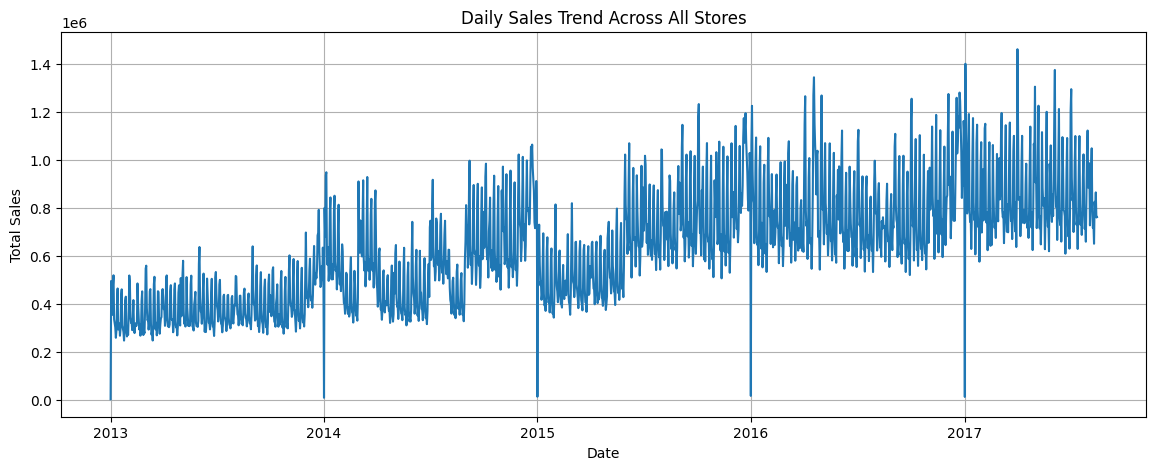

In [6]:
import matplotlib.pyplot as plt

daily_sales = train.groupby("date")["sales"].sum()

plt.figure(figsize=(14, 5))
plt.plot(daily_sales.index, daily_sales.values)
plt.title("Daily Sales Trend Across All Stores")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.grid(True)
plt.show()

family
GROCERY I        3.434627e+08
BEVERAGES        2.169545e+08
PRODUCE          1.227047e+08
CLEANING         9.752129e+07
DAIRY            6.448771e+07
BREAD/BAKERY     4.213395e+07
POULTRY          3.187600e+07
MEATS            3.108647e+07
PERSONAL CARE    2.459205e+07
DELI             2.411032e+07
Name: sales, dtype: float64


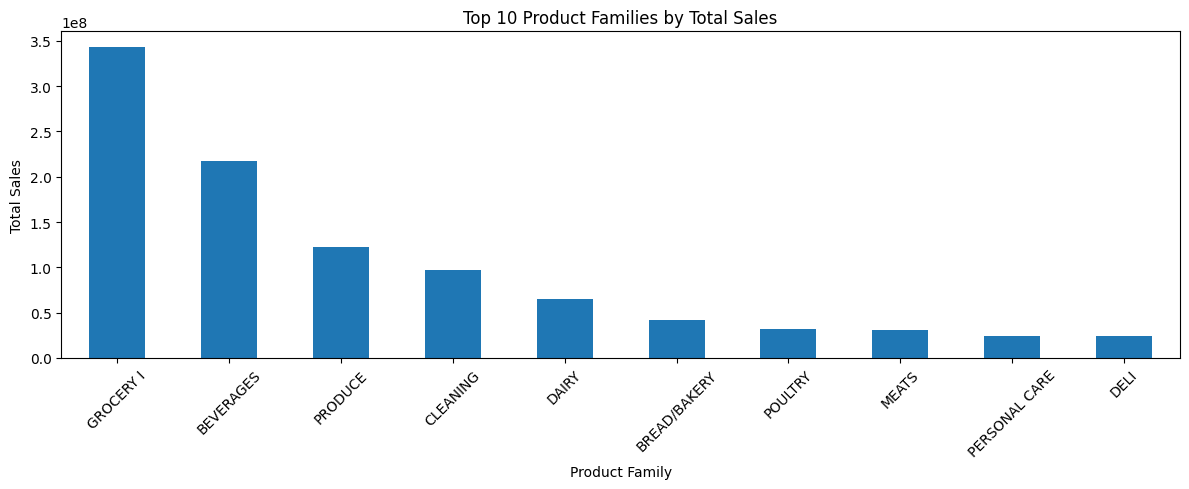

In [7]:
family_sales = train.groupby("family")["sales"].sum()
family_sales = family_sales.sort_values(ascending=False)

print(family_sales.head(10))

family_sales.head(10).plot(
    kind="bar",
    figsize=(12, 5),
    title="Top 10 Product Families by Total Sales"
)

plt.xlabel("Product Family")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [8]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split

# Use a smaller sample to make training faster
model_data = train.sample(n=200000, random_state=42).copy()

# Select features and target
features = ["store_nbr", "onpromotion", "year", "month",
            "day", "day_of_week"]

X = model_data[features]
y = model_data["sales"]

print("Sample size:", len(model_data))
print("Features:", features)
print("Data is ready for model training!")

Sample size: 200000
Features: ['store_nbr', 'onpromotion', 'year', 'month', 'day', 'day_of_week']
Data is ready for model training!


In [9]:
# Sort records by date
model_data = model_data.sort_values("date")

# Use earlier 80% of dates for training
split_date = model_data["date"].quantile(0.8)

train_data = model_data[model_data["date"] < split_date]
valid_data = model_data[model_data["date"] >= split_date]

X_train = train_data[features]
y_train = train_data["sales"]

X_valid = valid_data[features]
y_valid = valid_data["sales"]

print("Training rows:", len(X_train))
print("Validation rows:", len(X_valid))
print("Split date:", split_date)

Training rows: 159987
Validation rows: 40013
Split date: 2016-09-11 00:00:00


In [10]:
# Create the model
model = RandomForestRegressor(
    n_estimators=50,
    max_depth=12,
    random_state=42,
    n_jobs=-1
)

# Train the model
model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [11]:
# Predict sales for the validation data
predictions = model.predict(X_valid)

# Calculate evaluation metrics
mae = mean_absolute_error(y_valid, predictions)

print("Model Evaluation Results")
print("------------------------")
print("Mean Absolute Error (MAE):", round(mae, 2))

Model Evaluation Results
------------------------
Mean Absolute Error (MAE): 490.77


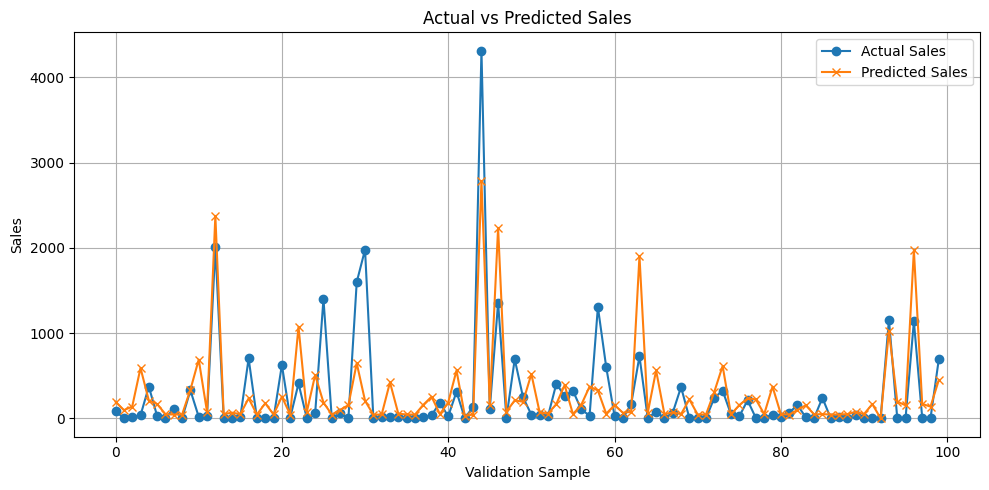

In [12]:
plt.figure(figsize=(10, 5))

plt.plot(
    y_valid.iloc[:100].values,
    label="Actual Sales",
    marker="o"
)

plt.plot(
    predictions[:100],
    label="Predicted Sales",
    marker="x"
)

plt.title("Actual vs Predicted Sales")
plt.xlabel("Validation Sample")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [13]:
results = pd.DataFrame({
    "Metric": ["Mean Absolute Error"],
    "Value": [round(mae, 2)]
})

results.to_csv(
    "/kaggle/working/model_evaluation.csv",
    index=False
)

print(results)
print("Evaluation results saved successfully!")

                Metric   Value
0  Mean Absolute Error  490.77
Evaluation results saved successfully!


In [14]:
# Check the date range used in our training and validation data

print("Training period:")
print(train_data["date"].min(), "to", train_data["date"].max())

print("\nValidation period:")
print(valid_data["date"].min(), "to", valid_data["date"].max())

Training period:
2013-01-01 00:00:00 to 2016-09-10 00:00:00

Validation period:
2016-09-11 00:00:00 to 2017-08-15 00:00:00


In [15]:
# Include product family in the forecasting model
model_data = model_data.sort_values("date").copy()

# Convert product families into numerical columns
model_data = pd.get_dummies(
    model_data,
    columns=["family"],
    dtype=int
)

# Select all input features, excluding date, sales, and ID
features = [
    col for col in model_data.columns
    if col not in ["date", "sales", "id"]
]

# Keep the same chronological split
train_data = model_data[model_data["date"] < split_date]
valid_data = model_data[model_data["date"] >= split_date]

X_train = train_data[features]
y_train = train_data["sales"]

X_valid = valid_data[features]
y_valid = valid_data["sales"]

print("Training rows:", len(X_train))
print("Validation rows:", len(X_valid))
print("Number of features:", len(features))
print("Product family included successfully!")

Training rows: 159987
Validation rows: 40013
Number of features: 39
Product family included successfully!


In [16]:
# Train an improved Random Forest model
model_improved = RandomForestRegressor(
    n_estimators=50,
    max_depth=12,
    random_state=42,
    n_jobs=-1
)

model_improved.fit(X_train, y_train)

print("Improved model training completed!")

Improved model training completed!


In [17]:
# Predict sales using the improved model
improved_predictions = model_improved.predict(X_valid)

# Calculate the new MAE
improved_mae = mean_absolute_error(
    y_valid,
    improved_predictions
)

print("Original Model MAE: 490.77")
print("Improved Model MAE:", round(improved_mae, 2))

if improved_mae < 490.77:
    print("The improved model has a lower MAE!")
else:
    print("The improved model did not lower the MAE.")

Original Model MAE: 490.77
Improved Model MAE: 167.07
The improved model has a lower MAE!


In [18]:
comparison = pd.DataFrame({
    "Model": [
        "Original Random Forest",
        "Improved Random Forest"
    ],
    "MAE": [
        490.77,
        round(improved_mae, 2)
    ]
})

print(comparison)

comparison.to_csv(
    "/kaggle/working/model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")

                    Model     MAE
0  Original Random Forest  490.77
1  Improved Random Forest  167.07
Model comparison saved successfully!


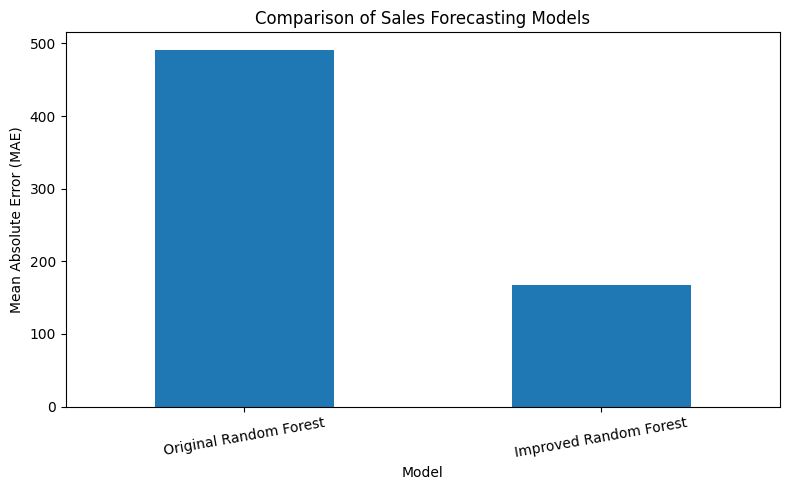

In [19]:
comparison.plot(
    x="Model",
    y="MAE",
    kind="bar",
    legend=False,
    figsize=(8, 5),
    title="Comparison of Sales Forecasting Models"
)

plt.ylabel("Mean Absolute Error (MAE)")
plt.xlabel("Model")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()